<a href="https://colab.research.google.com/github/hafizzx/Machine-Learning-Algorithms/blob/main/KNN_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [86]:
import numpy as np
import pandas as pd

In [87]:
df = pd.read_csv("/content/knn_student_performance_numeric_300.csv")
df.head(3)

,hours_studied,attendance_percent,previous_score,sleep_hours,result
0,7.7,86.7,58.2,6.3,1
1,4.4,48.1,80.9,4.8,1
2,8.6,72.2,92.3,3.3,1


In [88]:
df.shape

(300, 5)

In [90]:
X = df.iloc[:,:4]
X

,hours_studied,attendance_percent,previous_score,sleep_hours
0,7.7,86.7,58.2,6.3
1,4.4,48.1,80.9,4.8
2,8.6,72.2,92.3,3.3
3,7.0,70.9,77.7,6.4
4,0.9,91.5,97.1,9.7
...,...,...,...,...
295,9.0,56.7,90.5,4.3
296,9.8,82.2,42.2,4.5
297,8.0,78.0,36.2,7.6
298,7.8,98.9,34.9,5.0


In [91]:
y = df.iloc[:,4]
y

,result
0,1
1,1
2,1
3,1
4,1
...,...
295,1
296,1
297,1
298,1


In [93]:
from sklearn.model_selection import train_test_split

In [92]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size= 0.2 ,random_state=2)

In [94]:
X_train.shape

(240, 4)

In [95]:
X_test.shape

(60, 4)

In [96]:
y_train.shape

(240,)

This is for scaling the features values Coloms ki values ko ek jesa krny ky liye

In [66]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [14]:
X_train

array([[ 3.01540292e-01,  9.17218197e-01,  1.07943144e+00,
         1.56126898e+00],
       [-1.52261038e+00, -7.50851717e-01, -1.19761063e+00,
         4.18877043e-01],
       [-8.56093790e-01,  1.00532048e+00, -1.18058601e+00,
         9.15569188e-01],
       [ 6.52338499e-01,  2.00652952e-01, -8.61374510e-01,
        -1.22020704e+00],
       [ 4.41859575e-01, -4.27810008e-01, -3.25099183e-01,
         8.16230759e-01],
       [ 1.45917437e+00,  7.14362688e-02, -8.67545932e-02,
         1.20861755e-01],
       [-1.27705164e+00,  2.00652952e-01,  7.51707624e-01,
         1.56126898e+00],
       [ 6.52338499e-01, -1.98744069e-01,  1.49653447e+00,
        -1.07119939e+00],
       [-5.05295584e-01, -9.74044171e-01, -8.31581436e-01,
         1.51159976e+00],
       [-6.80694687e-01,  1.63965693e+00, -5.42163006e-01,
         1.41226133e+00],
       [-8.43377355e-02, -8.15460059e-01,  1.02835759e+00,
         1.46193055e+00],
       [ 1.73981294e+00,  1.31074173e+00, -5.88980693e-01,
      

In [97]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

In [77]:
knn = KNeighborsClassifier(n_neighbors=3)

In [98]:
knn.fit(X_train,y_train)

KNeighborsClassifier(n_neighbors=1)

In [99]:
pred = knn.predict(X_test)

In [100]:
accuracy_score(y_test,pred)

0.8166666666666667

**By using Cross Validation KNN model**

In [101]:
scores = []
for i in range(1,16):
  knn = KNeighborsClassifier(n_neighbors=1)
  knn.fit(X_train,y_train)
  pred = knn.predict(X_test)
  scores.append(accuracy_score(y_test,pred))

In [102]:
scores

[0.8166666666666667,
 0.8166666666666667,
 0.8166666666666667,
 0.8166666666666667,
 0.8166666666666667,
 0.8166666666666667,
 0.8166666666666667,
 0.8166666666666667,
 0.8166666666666667,
 0.8166666666666667,
 0.8166666666666667,
 0.8166666666666667,
 0.8166666666666667,
 0.8166666666666667,
 0.8166666666666667]

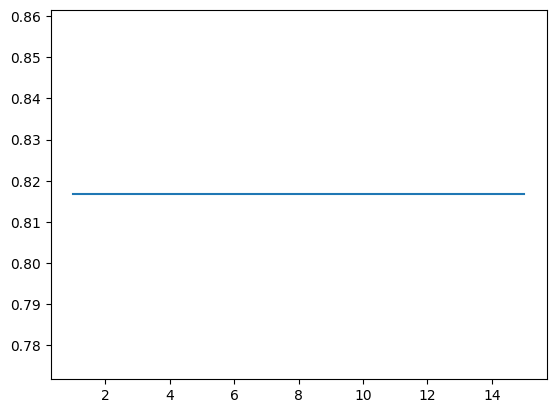

In [103]:
from matplotlib.pyplot import plot
plot(range(1,16),scores)